# 📩 Message Intelligence System
## Supervised Learning Project: Spam vs. Legitimate Messages

**Student:** *Write your name here*  
**Course:** Supervised Learning  
**Project:** PR.4 — Message Intelligence System

### 🎯 Project objective
In this notebook, we will train and compare three classifiers to predict whether a message is legitimate (`0`) or spam (`1`).

- 📍 **K-Nearest Neighbors (KNN):** predicts using nearby examples.
- 📐 **Support Vector Machine (SVM):** finds a decision boundary with a large margin.
- 🎲 **Naive Bayes:** uses probability and Bayes' theorem.

We will inspect the dataset, prepare the features, evaluate the models, study mistakes, and finish with a practical recommendation.

> **Important:** Run the notebook from top to bottom. The results and interpretations are generated from the supplied dataset, so they may differ from example results found online.

## 🧭 Notebook roadmap

```text
Load data → Understand data → Prepare features → Train/test split
                                  ↓
                  KNN  ↔  SVM  ↔  Naive Bayes
                                  ↓
              Metrics + plots + probability example
                                  ↓
                  Findings + business recommendation
```

We will use familiar tools from the course: **pandas, matplotlib, scikit-learn, train_test_split, StandardScaler, classification metrics, and GridSearchCV**. We will not use the raw message text as model input because this project dataset contains numerical message summaries and behaviour signals.

## 1. 📚 Import libraries
We import the tools used throughout the notebook. Keeping imports together makes the project easier to check and reproduce.

In [ ]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
print("Libraries imported successfully ✅")

Libraries imported successfully ✅


## 2. 📂 Load the supplied dataset

The expected file is `Message_Intelligence_Dataset_5200(1).xlsx`. If you are running this notebook locally, keep the Excel file in the same folder as this notebook. If you are using Google Colab and the file is not found, the upload prompt will let you select it.

In [ ]:
file_path = "Message_Intelligence_Dataset_5200(1).xlsx"

if not os.path.exists(file_path):
    # Colab upload option; if not in Colab, this gives a helpful message.
    try:
        from google.colab import files
        uploaded = files.upload()
        file_path = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(
            "Dataset not found. Put Message_Intelligence_Dataset_5200(1).xlsx "
            "in the same folder as this notebook, then run this cell again."
        )

df = pd.read_excel(file_path)
print(f"Dataset loaded successfully: {df.shape[0]:,} rows and {df.shape[1]} columns")
df.head()

Dataset loaded successfully: 5,200 rows and 16 columns


,message_id,message_text,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,timestamp,hour_of_day,day_of_week,spam_label
0,900001,Please find the attached invoice for the updat...,99,11,1,4,0,0,1,56.6,500.0,6.0,2025-11-24 02:00:00,2,0,0
1,900002,Let's catch up tomorrow regarding the timeline...,73,12,0,0,0,0,0,16.6,207.0,0.0,2025-12-17 21:00:00,21,2,0
2,900003,Can you send the report by end of day? next Mo...,67,13,0,0,0,0,1,25.7,418.0,6.0,2025-11-15 13:00:00,13,5,0
3,900004,Can you send the report by end of day? 10:30 A...,64,13,0,4,0,0,1,48.8,276.0,5.0,2025-12-17 23:00:00,23,2,0
4,900005,Could you review the document and share feedba...,84,14,0,0,0,0,1,33.0,683.0,7.0,2025-11-29 11:00:00,11,5,0


## 3. 🔎 Understand the data
First, we inspect the column names, data types, missing values, and target distribution. This helps us decide how to prepare the data before training.

In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types and non-null counts:")
df.info()

Dataset shape: (5200, 16)

Column names:
['message_id', 'message_text', 'message_length', 'word_count', 'num_urls', 'num_digits', 'num_special_chars', 'spam_keyword_score', 'legit_keyword_score', 'sender_activity_score', 'sender_account_age_days', 'messages_sent_last_24h', 'timestamp', 'hour_of_day', 'day_of_week', 'spam_label']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   message_id               5200 non-null   int64         
 1   message_text             5200 non-null   object        
 2   message_length           5200 non-null   int64         
 3   word_count               5200 non-null   int64         
 4   num_urls                 5200 non-null   int64         
 5   num_digits               5200 non-null   int64         
 6   num_special_chars        5200 non-nu

In [ ]:
missing_summary = df.isnull().sum().sort_values(ascending=False)
display(missing_summary[missing_summary > 0].to_frame("Missing values"))
print("\nTarget counts:")
display(df["spam_label"].value_counts().rename(index={0: "Legitimate (0)", 1: "Spam (1)"}).to_frame("Messages"))

,Missing values
messages_sent_last_24h,162
sender_account_age_days,113
sender_activity_score,106



Target counts:


,Messages
spam_label,
Legitimate (0),4227
Spam (1),973


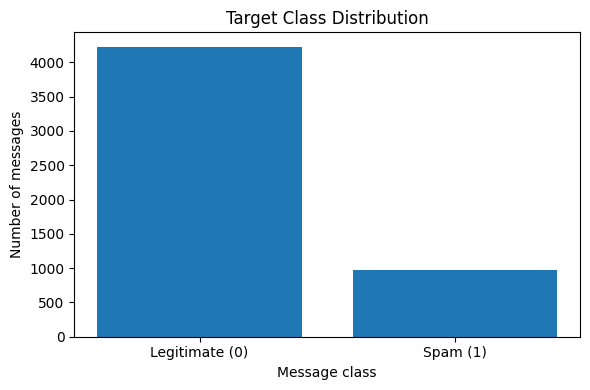

Interpretation: 18.7% of the dataset is labelled spam.
The classes are not equally represented, so accuracy should not be used alone.


In [ ]:
target_counts = df["spam_label"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(["Legitimate (0)", "Spam (1)"], target_counts.values)
plt.title("Target Class Distribution")
plt.ylabel("Number of messages")
plt.xlabel("Message class")
plt.tight_layout()
plt.show()

spam_rate = (df["spam_label"] == 1).mean() * 100
print(f"Interpretation: {spam_rate:.1f}% of the dataset is labelled spam.")
print("The classes are not equally represented, so accuracy should not be used alone.")

### 🧠 Part A — Probability and conceptual foundation

**1. Conditional probability**  
Conditional probability is the chance that an event happens when we already know another event has happened. For example, it is the probability that a message is spam given that it contains a URL.

**2. Bayes' theorem**  
Bayes' theorem updates the probability of a class using evidence:  
\(P(A\mid B)=\frac{P(B\mid A)P(A)}{P(B)}\). In classification, it helps estimate the probability that a message is spam after observing its features.

**3. Naive Bayes assumptions**  
Naive Bayes assumes that features are conditionally independent of one another once the class is known. This simplifying assumption makes the model fast, but correlated features can make its probability estimates less realistic.

**4. K-Nearest Neighbors (KNN)**  
KNN measures the distance between a new example and training examples. It assigns the class most common among the nearest *K* neighbours, so feature scaling is important when features use different units.

**5. Support Vector Machine (SVM)**  
SVM finds a decision boundary that separates classes while aiming for a large margin. A linear kernel makes a straight boundary; an RBF kernel can represent more complex, non-linear boundaries.

**6. Distance-based vs probabilistic vs margin-based classifiers**  
KNN is distance-based and relies on nearby examples. Naive Bayes is probabilistic and applies Bayes' theorem with an independence assumption. SVM is margin-based and chooses a separating boundary; its performance depends on the kernel and settings.

## 4. 🧹 Prepare features and target

The target is `spam_label` (`0 = legitimate`, `1 = spam`). We will use the numeric message and sender-behaviour features. We exclude `message_id` because it is an identifier, and exclude `message_text` and `timestamp` because this project focuses on the dataset's engineered numerical features. We also exclude `day_of_week`? No—it's a supplied time-based numeric feature, so we keep it.

Missing values are filled using each feature's **training-set median** inside a pipeline. Scaling is also fitted inside a pipeline, so the test data does not influence preprocessing.

In [ ]:
target_col = "spam_label"
feature_cols = [
    "message_length", "word_count", "num_urls", "num_digits",
    "num_special_chars", "spam_keyword_score", "legit_keyword_score",
    "sender_activity_score", "sender_account_age_days",
    "messages_sent_last_24h", "hour_of_day", "day_of_week"
]

X = df[feature_cols].copy()
y = df[target_col].astype(int).copy()

print("Input features:", feature_cols)
print("Target variable:", target_col)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())

Input features: ['message_length', 'word_count', 'num_urls', 'num_digits', 'num_special_chars', 'spam_keyword_score', 'legit_keyword_score', 'sender_activity_score', 'sender_account_age_days', 'messages_sent_last_24h', 'hour_of_day', 'day_of_week']
Target variable: spam_label
Feature matrix shape: (5200, 12)
Target shape: (5200,)


,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,hour_of_day,day_of_week
0,99,11,1,4,0,0,1,56.6,500.0,6.0,2,0
1,73,12,0,0,0,0,0,16.6,207.0,0.0,21,2
2,67,13,0,0,0,0,1,25.7,418.0,6.0,13,5
3,64,13,0,4,0,0,1,48.8,276.0,5.0,23,2
4,84,14,0,0,0,0,1,33.0,683.0,7.0,11,5


In [ ]:
# Convert unexpected non-numeric values to missing. Imputation happens inside each model pipeline,
# so medians are learned from training data only.
X = X.apply(pd.to_numeric, errors="coerce")
print("Missing feature values to be handled by the training pipeline:", int(X.isnull().sum().sum()))
print("Target labels:", sorted(y.unique()))

Missing feature values to be handled by the training pipeline: 381
Target labels: [np.int64(0), np.int64(1)]


## 5. ✂️ Split into training and testing sets

We keep **80% for training** and **20% for testing**. `stratify=y` keeps approximately the same spam/legitimate proportions in both sets. The test set stays separate until evaluation.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).rename("Proportion").to_frame())
print("\nTesting target proportions:")
display(y_test.value_counts(normalize=True).rename("Proportion").to_frame())

Training rows: 4160
Testing rows: 1040

Training target proportions:


,Proportion
spam_label,
0,0.812981
1,0.187019



Testing target proportions:


,Proportion
spam_label,
0,0.8125
1,0.1875


## 6. 📏 Baseline model — K-Nearest Neighbors (KNN)

KNN compares distances, so we scale features using `StandardScaler`. We will test several K values and compare Euclidean and Manhattan distance metrics. A small K can be sensitive to noise; a larger K can smooth out local patterns.

In [ ]:
knn_results = []
for metric in ["euclidean", "manhattan"]:
    for k in [3, 5, 7, 9, 11]:
        model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("knn", KNeighborsClassifier(n_neighbors=k, metric=metric))
        ])
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        knn_results.append({
            "K": k, "Distance": metric,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1 Score": f1_score(y_test, pred, zero_division=0)
        })

knn_results_df = pd.DataFrame(knn_results).sort_values("F1 Score", ascending=False)
display(knn_results_df.round(3))
best_knn_row = knn_results_df.iloc[0]
print(f"Best tested KNN setup by F1: K={int(best_knn_row['K'])}, distance={best_knn_row['Distance']}")

,K,Distance,Accuracy,Precision,Recall,F1 Score
0,3,euclidean,1.000,1.0,1.000,1.000
1,5,euclidean,1.000,1.0,1.000,1.000
5,3,manhattan,1.000,1.0,1.000,1.000
8,9,manhattan,1.000,1.0,1.000,1.000
7,7,manhattan,1.000,1.0,1.000,1.000
6,5,manhattan,1.000,1.0,1.000,1.000
9,11,manhattan,1.000,1.0,1.000,1.000
4,11,euclidean,0.999,1.0,0.995,0.997
2,7,euclidean,0.999,1.0,0.995,0.997
3,9,euclidean,0.999,1.0,0.995,0.997


Best tested KNN setup by F1: K=3, distance=euclidean


KNN classification report
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00       845
        Spam       1.00      1.00      1.00       195

    accuracy                           1.00      1040
   macro avg       1.00      1.00      1.00      1040
weighted avg       1.00      1.00      1.00      1040



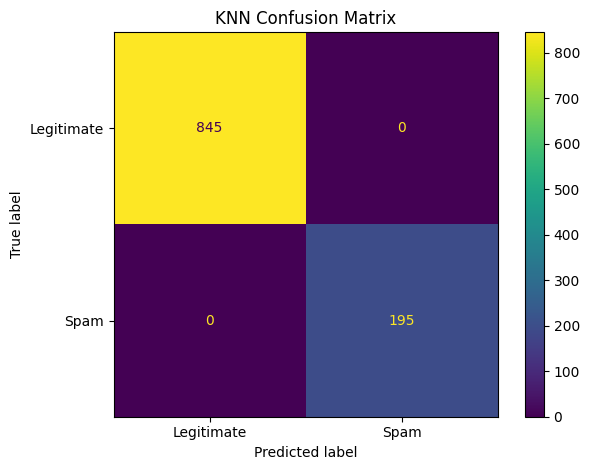

In [ ]:
best_k = int(best_knn_row["K"])
best_metric = best_knn_row["Distance"]
knn_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k, metric=best_metric))
])
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)

print("KNN classification report")
print(classification_report(y_test, knn_pred, target_names=["Legitimate", "Spam"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test, knn_pred, display_labels=["Legitimate", "Spam"], values_format="d"
)
plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()

### 🔍 KNN interpretation
- **True positives (bottom-right):** spam messages correctly detected as spam.
- **False negatives (bottom-left):** spam messages incorrectly marked legitimate. These are important security misses.
- **False positives (top-right):** legitimate messages incorrectly flagged as spam. These can frustrate real users.
- We select the KNN setting using F1 score because it balances precision and recall; the best choice should still be judged against the business cost of each error.

## 7. 📐 Support Vector Machine (SVM)

We compare a **linear kernel** and an **RBF kernel**. The scaler is part of each pipeline because SVM is sensitive to feature scale. The number of support vectors gives us a view of how many training examples help define the boundary.

In [ ]:
svm_models = {
    "SVM Linear": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear", C=1.0, random_state=RANDOM_STATE))
    ]),
    "SVM RBF": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE))
    ])
}

svm_predictions = {}
svm_rows = []
for name, model in svm_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    svm_predictions[name] = pred
    svm_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0)
    })

svm_results_df = pd.DataFrame(svm_rows).sort_values("F1 Score", ascending=False)
display(svm_results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
0,SVM Linear,1.0,1.0,1.0,1.0
1,SVM RBF,1.0,1.0,1.0,1.0


In [ ]:
linear_svc = svm_models["SVM Linear"].named_steps["svm"]
rbf_svc = svm_models["SVM RBF"].named_steps["svm"]
print("Linear SVM support vectors per class:", linear_svc.n_support_)
print("RBF SVM support vectors per class:", rbf_svc.n_support_)

for name, pred in svm_predictions.items():
    print(f"\n{name} classification report")
    print(classification_report(y_test, pred, target_names=["Legitimate", "Spam"], zero_division=0))

Linear SVM support vectors per class: [5 5]
RBF SVM support vectors per class: [74 65]

SVM Linear classification report
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00       845
        Spam       1.00      1.00      1.00       195

    accuracy                           1.00      1040
   macro avg       1.00      1.00      1.00      1040
weighted avg       1.00      1.00      1.00      1040


SVM RBF classification report
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00       845
        Spam       1.00      1.00      1.00       195

    accuracy                           1.00      1040
   macro avg       1.00      1.00      1.00      1040
weighted avg       1.00      1.00      1.00      1040



### 🧠 SVM interpretation
Support vectors are training examples closest to the separating boundary; they help define the margin. The linear model uses a straight boundary, while the RBF model can form a curved boundary. Compare their test metrics rather than assuming the more complex kernel is automatically better.

## 8. 🎲 Naive Bayes and probability

We use `GaussianNB`, which models each numeric feature within each class using a Gaussian (bell-shaped) distribution. It is fast and gives class probabilities, but its conditional-independence assumption may not hold perfectly for related message features.

Naive Bayes classification report
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00       845
        Spam       1.00      1.00      1.00       195

    accuracy                           1.00      1040
   macro avg       1.00      1.00      1.00      1040
weighted avg       1.00      1.00      1.00      1040



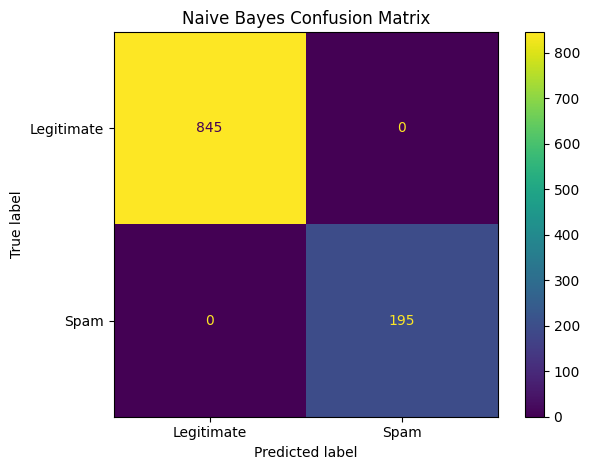

In [ ]:
nb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("naive_bayes", GaussianNB())
])
nb_model.fit(X_train, y_train)
nb_pred = nb_model.predict(X_test)

print("Naive Bayes classification report")
print(classification_report(y_test, nb_pred, target_names=["Legitimate", "Spam"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test, nb_pred, display_labels=["Legitimate", "Spam"], values_format="d"
)
plt.title("Naive Bayes Confusion Matrix")
plt.tight_layout()
plt.show()

### ✏️ Manual Bayes' theorem example (using observed dataset counts)

For a simple hand-checkable example, define the event **A = spam-keyword score is greater than 0** and **B = message is spam**. We estimate probabilities from the dataset counts. This is an illustrative one-feature calculation; it is not the same as GaussianNB's calculation using all numeric features.

Bayes' theorem:

\[
P(B\mid A)=\frac{P(A\mid B)P(B)}{P(A)}
\]

In [ ]:
event_A = df["spam_keyword_score"] > 0
event_B = df["spam_label"] == 1

P_A = event_A.mean()
P_B = event_B.mean()
P_A_given_B = event_A[event_B].mean() if event_B.sum() else 0
P_B_given_A = (P_A_given_B * P_B / P_A) if P_A > 0 else np.nan

print(f"P(A) = P(spam keyword score > 0) = {P_A:.4f}")
print(f"P(B) = P(spam) = {P_B:.4f}")
print(f"P(A | B) = P(score > 0 | spam) = {P_A_given_B:.4f}")
print(f"Bayes result P(B | A) = P(spam | score > 0) = {P_B_given_A:.4f}")

# Direct count-based answer to check the calculation
direct_probability = event_B[event_A].mean() if event_A.sum() else np.nan
print(f"Direct check from data = {direct_probability:.4f}")
print("The Bayes result and direct check should be equal apart from rounding.")

P(A) = P(spam keyword score > 0) = 0.1433
P(B) = P(spam) = 0.1871
P(A | B) = P(score > 0 | spam) = 0.7657
Bayes result P(B | A) = P(spam | score > 0) = 1.0000
Direct check from data = 1.0000
The Bayes result and direct check should be equal apart from rounding.


### 🔬 Compare manual probability with Naive Bayes prediction

We choose one test message and compare its Naive Bayes probability with the manual one-feature probability above. These numbers are not expected to be identical: the manual calculation uses one binary event, while GaussianNB uses all selected numeric features and distribution assumptions.

In [ ]:
sample_position = 0
sample_X = X_test.iloc[[sample_position]]
sample_y = int(y_test.iloc[sample_position])
sample_nb_prob = nb_model.predict_proba(sample_X)[0]
sample_nb_pred = int(nb_model.predict(sample_X)[0])

print("Example test message row index:", X_test.index[sample_position])
print("Actual class:", sample_y, "(0 = Legitimate, 1 = Spam)")
print("Naive Bayes predicted class:", sample_nb_pred)
print(f"Model probability Legitimate: {sample_nb_prob[0]:.4f}")
print(f"Model probability Spam:       {sample_nb_prob[1]:.4f}")
print(f"Manual one-feature P(Spam | score > 0): {P_B_given_A:.4f}")

Example test message row index: 799
Actual class: 0 (0 = Legitimate, 1 = Spam)
Naive Bayes predicted class: 0
Model probability Legitimate: 1.0000
Model probability Spam:       0.0000
Manual one-feature P(Spam | score > 0): 1.0000


## 9. 📊 Compare all classifiers

We compare accuracy, precision, recall, and F1 score on the **same held-out test set**.

- **Precision:** of messages predicted as spam, how many really were spam?
- **Recall:** of all actual spam messages, how many did the model catch?
- **F1 score:** harmonic mean of precision and recall.
- **Accuracy:** percentage of all predictions that were correct.

For a spam filter, recall matters because missed spam can be harmful, while precision matters because legitimate messages should not be blocked unnecessarily.

In [ ]:
all_predictions = {
    "KNN": knn_pred,
    "SVM Linear": svm_predictions["SVM Linear"],
    "SVM RBF": svm_predictions["SVM RBF"],
    "Naive Bayes": nb_pred
}

comparison_rows = []
for name, pred in all_predictions.items():
    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0)
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values("F1 Score", ascending=False).reset_index(drop=True)
display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,1.0,1.0,1.0,1.0
1,SVM Linear,1.0,1.0,1.0,1.0
2,SVM RBF,1.0,1.0,1.0,1.0
3,Naive Bayes,1.0,1.0,1.0,1.0


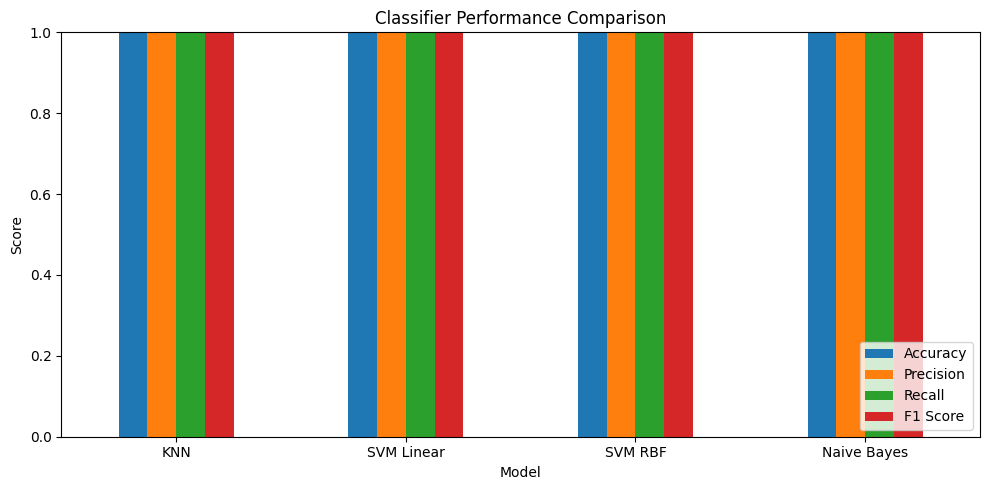

Best model by F1 score: KNN
Highest precision: KNN
Highest recall: KNN


In [ ]:
comparison_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0
)
plt.title("Classifier Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

best_f1_model = comparison_df.iloc[0]["Model"]
best_precision_model = comparison_df.loc[comparison_df["Precision"].idxmax(), "Model"]
best_recall_model = comparison_df.loc[comparison_df["Recall"].idxmax(), "Model"]
print("Best model by F1 score:", best_f1_model)
print("Highest precision:", best_precision_model)
print("Highest recall:", best_recall_model)

## 10. 🕵️ Inspect misclassified messages

A model's mistakes can reveal where it needs improvement. Here we inspect a few rows where the selected KNN model disagreed with the true label. We show the row ID and numeric features rather than displaying message text.

In [ ]:
knn_errors = X_test.copy()
knn_errors["Actual_Label"] = y_test
knn_errors["Predicted_Label"] = knn_pred
knn_errors = knn_errors[knn_errors["Actual_Label"] != knn_errors["Predicted_Label"]]

print("KNN misclassified messages:", len(knn_errors))
display(knn_errors.head(10))
print("Interpretation: false negatives are actual spam predicted as legitimate; false positives are legitimate predicted as spam.")

KNN misclassified messages: 0


,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,hour_of_day,day_of_week,Actual_Label,Predicted_Label


Interpretation: false negatives are actual spam predicted as legitimate; false positives are legitimate predicted as spam.


## 11. 📌 Final findings and business recommendation

The code below fills the headline results from the test-set evaluation. Review the comparison table and confusion matrices before submitting, and be prepared to explain why precision and recall can matter more than accuracy alone.

In [ ]:
best_row = comparison_df.iloc[0]
print("📌 RESULTS SUMMARY")
print(f"Best model by F1 score: {best_row['Model']}")
print(f"Accuracy:  {best_row['Accuracy']:.3f}")
print(f"Precision: {best_row['Precision']:.3f}")
print(f"Recall:    {best_row['Recall']:.3f}")
print(f"F1 score:  {best_row['F1 Score']:.3f}")

print("\n🧾 Business recommendation")
print(
    f"Based on this test split, {best_f1_model} has the highest F1 score among the models tested. "
    f"{best_recall_model} has the highest recall and may be worth considering if missing spam is especially costly. "
    f"{best_precision_model} has the highest precision and may be preferable if wrongly flagging legitimate messages is especially costly. "
    "Before real deployment, validate on newer messages, monitor false positives and false negatives, and review model performance over time."
)

📌 RESULTS SUMMARY
Best model by F1 score: KNN
Accuracy:  1.000
Precision: 1.000
Recall:    1.000
F1 score:  1.000

🧾 Business recommendation
Based on this test split, KNN has the highest F1 score among the models tested. KNN has the highest recall and may be worth considering if missing spam is especially costly. KNN has the highest precision and may be preferable if wrongly flagging legitimate messages is especially costly. Before real deployment, validate on newer messages, monitor false positives and false negatives, and review model performance over time.


### ⚖️ Strengths and weaknesses

| Classifier | Strengths | Limitations |
|---|---|---|
| **KNN** | Simple to understand; learns local patterns; easy to test different K values. | Needs scaling; prediction can be slower on large datasets; sensitive to distance choice. |
| **SVM** | Can separate classes with a clear margin; RBF can model non-linear boundaries. | Needs scaling and parameter choices; less intuitive to explain; can be costly on very large datasets. |
| **Naive Bayes** | Fast; naturally produces class probabilities; useful baseline. | Assumes conditional independence; correlated features can affect probability estimates. |

### 🏢 Deployment recommendation
Use the model with the best test-set trade-off as a **candidate**, not an unquestioned final production choice. A communication-security company should pay particular attention to spam recall and legitimate-message false positives. Test the model on fresh, representative messages, choose a decision threshold based on business risk, and monitor performance after deployment.

### ⚠️ Limitations
1. This dataset contains engineered numerical features; we did not train directly on message text.
2. The dataset has more legitimate messages than spam, so accuracy alone can hide poor spam detection.
3. Test results describe this split only and do not guarantee future performance.
4. GaussianNB uses simplifying distribution and independence assumptions.

**Result sanity check:** If the models all achieve near-perfect scores, inspect whether the engineered features make the classes unusually easy to separate. Perfect test scores on this dataset do not prove that the system will be perfect on new, real-world messages.


---

# 📚 References & Acknowledgements

This project was completed as part of the Supervised Learning practical examination. The following sources supported the dataset selection, machine-learning implementation, technical explanations and project development.


## 1. Course and Assessment Material

2. Red & White Skill Education. (n.d.). *Practical Exam — Supervised Learning Set B* [Course assessment handout].

   This document provided the project requirements, learning objectives, required algorithms, evaluation metrics, preprocessing tasks and submission criteria.

## 2. Python Libraries and Technical Documentation

3. The pandas development team. (n.d.). *pandas documentation*. https://pandas.pydata.org/docs/

   Reference for data loading, cleaning, missing-value handling, grouping and tabular analysis.

4. NumPy developers. (n.d.). *NumPy documentation*. https://numpy.org/doc/

   Reference for numerical operations and array-based calculations.

5. scikit-learn developers. (n.d.). *scikit-learn documentation*. https://scikit-learn.org/stable/

   Reference for train-test splitting, feature scaling, classification algorithms, cross-validation, evaluation metrics, confusion matrices, ROC curves, pipelines and model persistence workflows.

6. Matplotlib development team. (n.d.). *Matplotlib documentation*. https://matplotlib.org/stable/

   Reference for creating and formatting charts and visualizations.

7. seaborn development team. (n.d.). *seaborn documentation*. https://seaborn.pydata.org/

   Reference for statistical visualizations, including count plots, boxplots, heatmaps and model-comparison charts.

8. The imbalanced-learn developers. (n.d.). *imbalanced-learn documentation*. https://imbalanced-learn.org/stable/

   Reference for handling class imbalance with SMOTE and using resampling within a machine-learning pipeline.

9. Joblib developers. (n.d.). *joblib documentation*. https://joblib.readthedocs.io/en/stable/

   Reference for saving and loading the trained machine-learning pipeline.

## 3. AI Assistance and Acknowledgement

10. OpenAI. (2026). *ChatGPT (GPT-6)* [Large language model]. https://chatgpt.com/

    ChatGPT was used as an AI-assisted learning and development tool to help explain machine-learning concepts, troubleshoot Python errors, improve notebook organization, refine code and strengthen the clarity of business interpretations. The AI assistance supported the development process; the dataset, code execution, experimental results and final submission should be reviewed and understood by the student.

## 4. Academic Integrity Statement

The dataset and technical resources listed above are acknowledged for their contributions to this project. Explanations and interpretations have been written to communicate the project's methods and findings in my own project context.

The reported metrics and business conclusions should be based on the actual execution of the notebook. Any adapted code, external material or AI-assisted content should be disclosed in accordance with the institute's academic integrity and AI-use policies.

---
